In [37]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    balanced_accuracy_score,
    roc_auc_score,roc_curve,
    precision_recall_curve,average_precision_score
)
# Classification models
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

from sklearn.naive_bayes import GaussianNB

from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    AdaBoostClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier,
    VotingClassifier,
    StackingClassifier
)

from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier


In [38]:
df = pd.read_csv('/content/bank.csv')

In [39]:
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit
0,59,admin.,married,secondary,no,2343.0,yes,no,unknown,5.0,may,1042.0,1.0,-1.0,0.0,unknown,yes
1,56,admin.,married,secondary,no,45.0,no,no,unknown,5.0,may,1467.0,1.0,-1.0,0.0,unknown,yes
2,41,technician,married,secondary,no,1270.0,yes,no,unknown,5.0,may,1389.0,1.0,-1.0,0.0,unknown,yes
3,54,admin.,married,tertiary,no,184.0,no,no,unknown,5.0,may,673.0,2.0,-1.0,0.0,unknown,yes
4,42,management,single,tertiary,no,0.0,yes,yes,unknown,5.0,may,562.0,2.0,-1.0,0.0,unknown,yes


In [40]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8912 entries, 0 to 8911
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   age        8912 non-null   int64  
 1   job        8905 non-null   object 
 2   marital    8743 non-null   object 
 3   education  8885 non-null   object 
 4   default    8908 non-null   object 
 5   balance    8899 non-null   float64
 6   housing    8899 non-null   object 
 7   loan       8882 non-null   object 
 8   contact    8881 non-null   object 
 9   day        8893 non-null   float64
 10  month      8884 non-null   object 
 11  duration   8905 non-null   float64
 12  campaign   8904 non-null   float64
 13  pdays      8767 non-null   float64
 14  previous   8909 non-null   float64
 15  poutcome   8912 non-null   object 
 16  deposit    8903 non-null   object 
dtypes: float64(6), int64(1), object(10)
memory usage: 1.2+ MB


In [41]:
df.describe()

,age,balance,day,duration,campaign,pdays,previous
count,8912.000000,8899.000000,8893.000000,8905.000000,8904.000000,8767.000000,8909.000000
mean,41.257855,1539.680638,15.684921,374.953734,2.512579,52.456941,0.834325
std,11.840567,3297.446702,8.406729,351.283501,2.772366,109.094161,2.304733
min,18.000000,-3058.000000,1.000000,3.000000,1.000000,-1.000000,0.000000
25%,32.000000,121.500000,8.000000,139.000000,1.000000,-1.000000,0.000000
50%,39.000000,553.000000,15.000000,256.000000,2.000000,-1.000000,0.000000
75%,49.000000,1726.000000,22.000000,501.000000,3.000000,64.000000,1.000000
max,95.000000,81204.000000,31.000000,3284.000000,63.000000,842.000000,58.000000


In [42]:
df.describe(include='object')

,job,marital,education,default,housing,loan,contact,month,poutcome,deposit
count,8905,8743,8885,8908,8899,8882,8881,8884,8912,8903
unique,12,3,4,2,2,2,3,12,4,2
top,management,married,secondary,no,no,no,cellular,may,unknown,no
freq,2078,4980,4364,8762,4657,7703,6381,2265,6638,4673


In [43]:
df.duplicated().sum()

np.int64(0)

In [44]:
df['deposit'].describe()

,deposit
count,8903
unique,2
top,no
freq,4673


In [45]:
df.isnull().sum()

,0
age,0
job,7
marital,169
education,27
default,4
balance,13
housing,13
loan,30
contact,31
day,19


In [46]:
df= df.drop(columns=['duration'])

In [47]:
df.dropna(inplace=True)

In [48]:
df.shape

(8719, 16)

<Axes: xlabel='deposit', ylabel='count'>

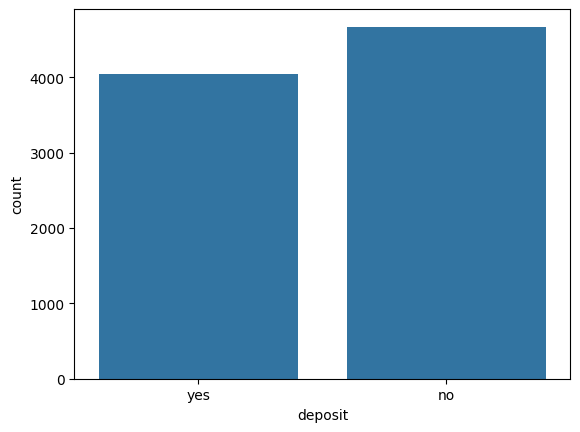

In [49]:
sns.countplot(data=df,x='deposit')

In [50]:
X= df.drop('deposit',axis=1)
y=df['deposit'].map({'yes':1, 'no':0})

In [51]:
X_train , X_test, y_train, y_test= train_test_split(X,y,
                                                    test_size=0.20,
                                                    random_state=42,
                                                    stratify=y )

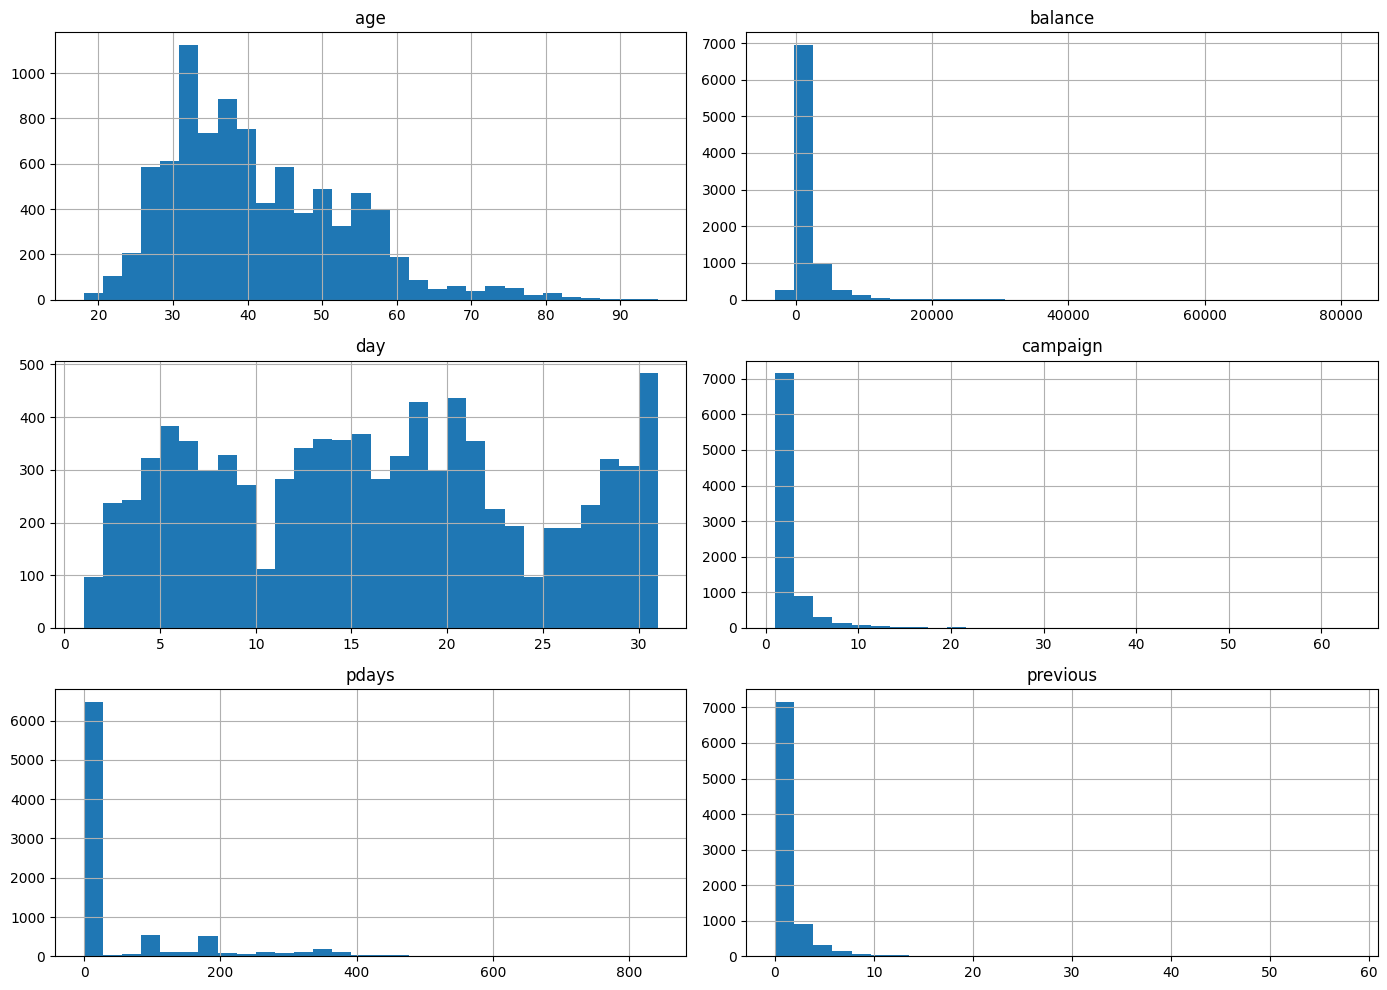

In [52]:
num_cols = [
    'age', 'balance', 'day',
    'campaign', 'pdays', 'previous'
]

# توزيع كل عمود
df[num_cols].hist(figsize=(14, 10), bins=30)
plt.tight_layout()
plt.show()

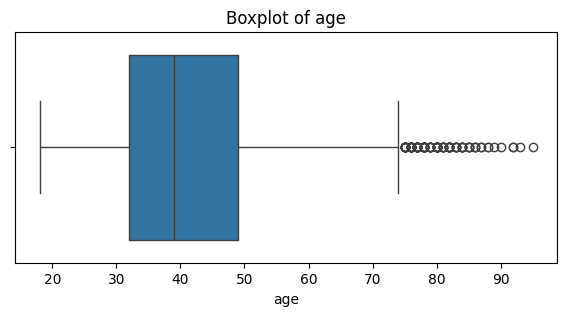

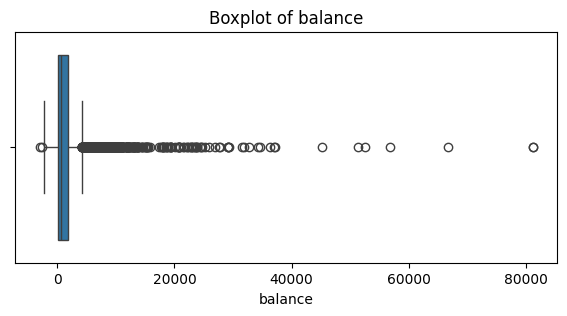

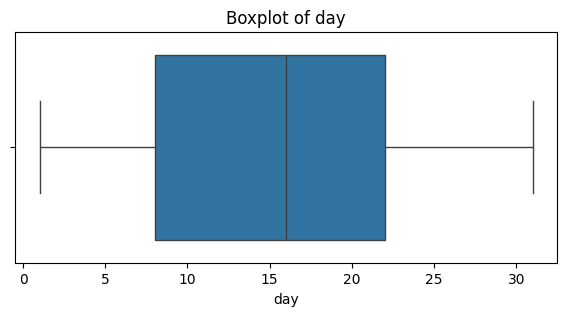

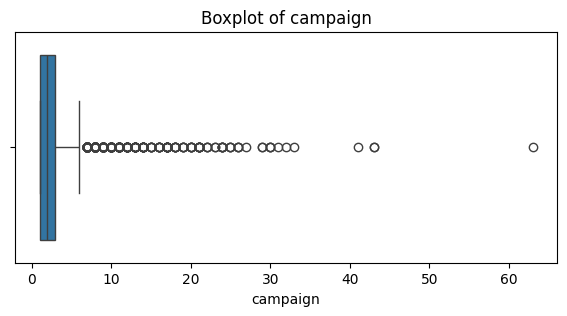

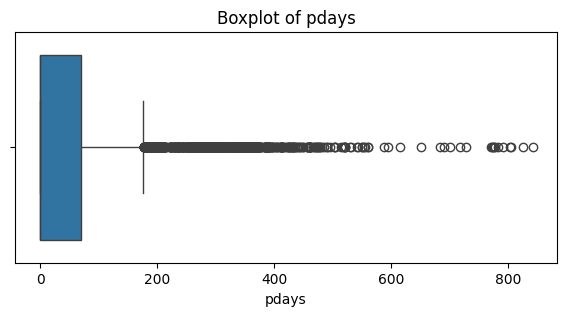

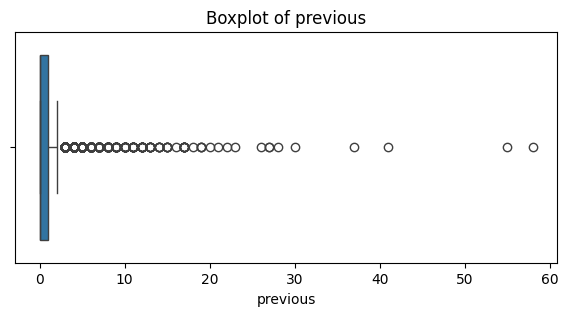

In [53]:
for col in num_cols:
    plt.figure(figsize=(7, 3))
    sns.boxplot(x=df[col])
    plt.title(f'Boxplot of {col}')
    plt.show()

In [54]:
cat_cols= ['job',	'marital',	'education',	'default',	'housing', 'loan',	'contact',	'month', 'poutcome',	'deposit']
for col in cat_cols:
    print(f"\n--- {col} ---")
    display(df[col].value_counts(dropna=False))


--- job ---


,count
job,
management,2048
blue-collar,1499
technician,1431
admin.,1040
services,724
retired,598
self-employed,308
unemployed,288
student,277



--- marital ---


,count
marital,
married,4969
single,2743
divorced,1007



--- education ---


,count
education,
secondary,4270
tertiary,2902
primary,1165
unknown,382


... (10 outputs left out)


--- poutcome ---


,count
poutcome,
unknown,6445
failure,979
success,880
other,415



--- deposit ---


,count
deposit,
no,4673
yes,4046


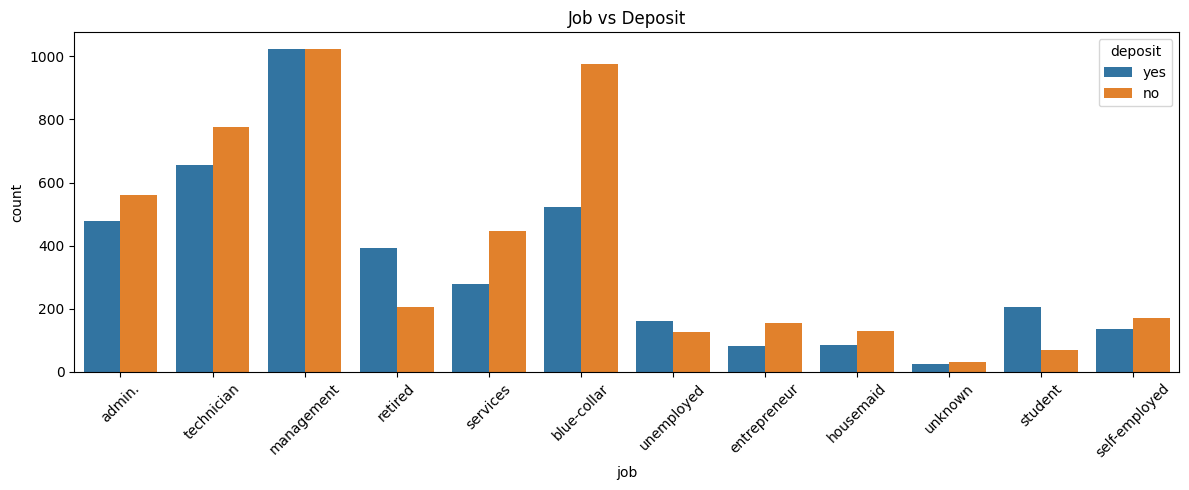

In [55]:
plt.figure(figsize=(12, 5))
sns.countplot(data=df, x='job', hue='deposit')
plt.xticks(rotation=45)
plt.title('Job vs Deposit')                             ##there is a relation
plt.tight_layout()
plt.show()

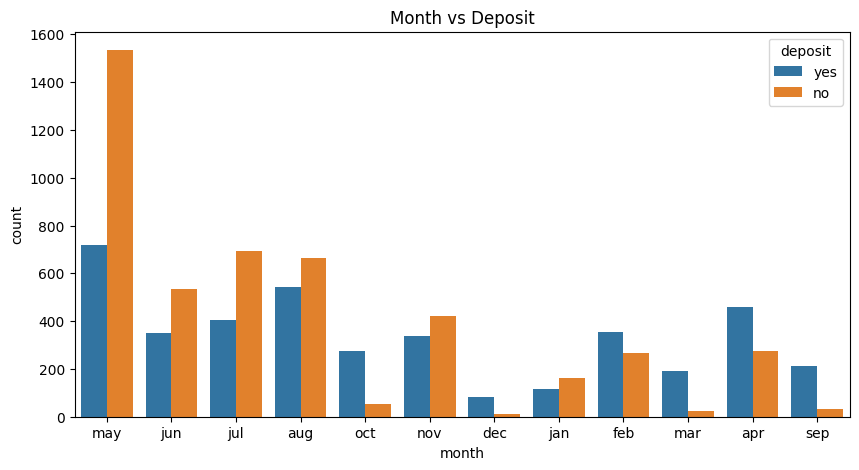

In [56]:
plt.figure(figsize=(10, 5))
sns.countplot(data=df, x='month', hue='deposit')
plt.title('Month vs Deposit')
plt.show()

In [57]:
display(
    pd.crosstab(
        df['housing'],
        df['deposit'],
        normalize='index'
    ) * 100
)

deposit,no,yes
housing,,
no,43.789704,56.210296
yes,64.371690,35.628310


In [58]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 8719 entries, 0 to 8911
Data columns (total 16 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   age        8719 non-null   int64  
 1   job        8719 non-null   object 
 2   marital    8719 non-null   object 
 3   education  8719 non-null   object 
 4   default    8719 non-null   object 
 5   balance    8719 non-null   float64
 6   housing    8719 non-null   object 
 7   loan       8719 non-null   object 
 8   contact    8719 non-null   object 
 9   day        8719 non-null   float64
 10  month      8719 non-null   object 
 11  campaign   8719 non-null   float64
 12  pdays      8719 non-null   float64
 13  previous   8719 non-null   float64
 14  poutcome   8719 non-null   object 
 15  deposit    8719 non-null   object 
dtypes: float64(5), int64(1), object(10)
memory usage: 1.1+ MB


In [59]:
cat_cols = X_train.select_dtypes(
    include=[ 'object', 'category']
).columns.tolist()

num_cols = X_train.select_dtypes(
    include=['number']
).columns.tolist()

print("Categorical columns:", cat_cols)
print("Numerical columns:", num_cols)

Categorical columns: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']
Numerical columns: ['age', 'balance', 'day', 'campaign', 'pdays', 'previous']


In [60]:
onehot = OneHotEncoder(
    handle_unknown='ignore',
    sparse_output=False
)

X_train_cat = onehot.fit_transform(X_train[cat_cols])
X_test_cat = onehot.transform(X_test[cat_cols])

In [61]:
scaler = StandardScaler()

X_train_num = scaler.fit_transform(X_train[num_cols])
X_test_num = scaler.transform(X_test[num_cols])

In [62]:
X_train = np.concatenate(
    [X_train_num, X_train_cat], axis=1
)

X_test = np.concatenate(
    [X_test_num, X_test_cat], axis=1
)

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)

Train shape: (6975, 50)
Test shape: (1744, 50)


In [63]:
models = {

    # Linear
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=1),

    # Distance-based
    "KNN": KNeighborsClassifier(n_neighbors=5),

    # SVM
    "SVC": SVC(probability=True, random_state=1),

    # Tree
    "Decision Tree": DecisionTreeClassifier(random_state=1),

    # Naive Bayes
    "Naive Bayes": GaussianNB(),

    # Bagging Based
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=1),
    "Extra Trees": ExtraTreesClassifier(n_estimators=100, random_state=1),

    # Boosting
    "AdaBoost": AdaBoostClassifier(random_state=1),
    "Gradient Boosting": GradientBoostingClassifier(random_state=1),
    "Hist Gradient Boosting": HistGradientBoostingClassifier(random_state=1),

    # External Boosting Libraries
    "XGBoost": XGBClassifier(eval_metric='logloss', random_state=1, use_label_encoder=False),
    "CatBoost": CatBoostClassifier(verbose=0, random_state=1),
    "LightGBM": LGBMClassifier(random_state=1)
}

  0%|          | 0/13 [00:00<?, ?it/s]


Confusion Matrix:
 [[749 186]
 [326 483]]


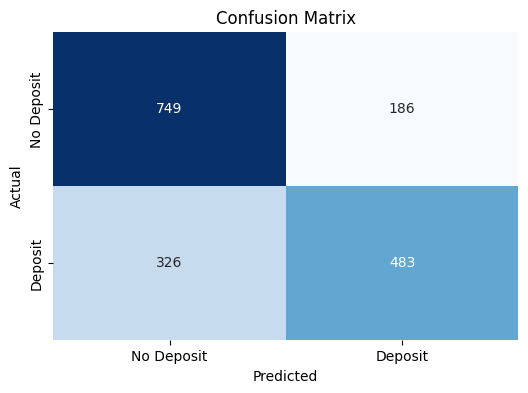


Classification Report:

              precision    recall  f1-score   support

  No Deposit       0.70      0.80      0.75       935
     Deposit       0.72      0.60      0.65       809

    accuracy                           0.71      1744
   macro avg       0.71      0.70      0.70      1744
weighted avg       0.71      0.71      0.70      1744

ROC-AUC: 0.7653880475664814


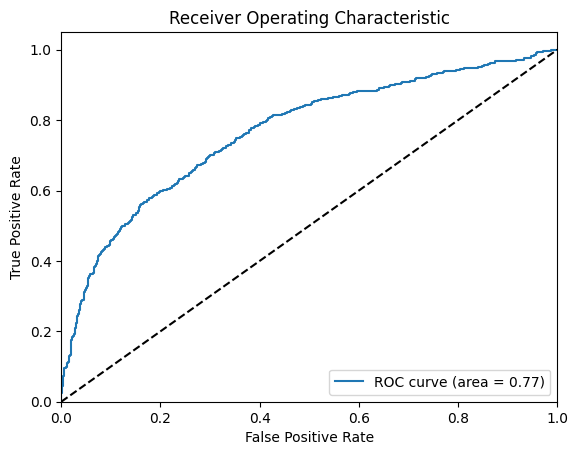

PR AUC: 0.7488933651140587


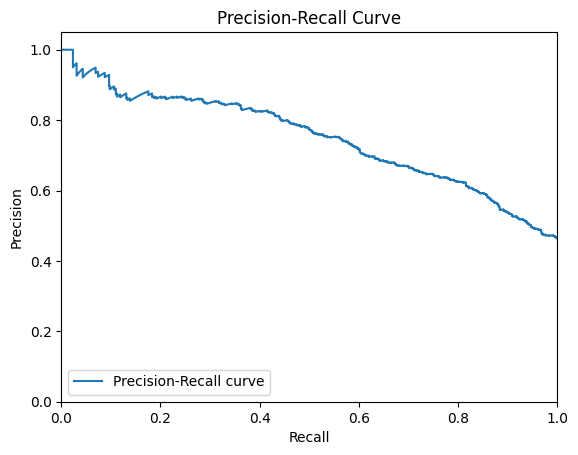

  8%|▊         | 1/13 [00:00<00:10,  1.18it/s]


Confusion Matrix:
 [[720 215]
 [323 486]]


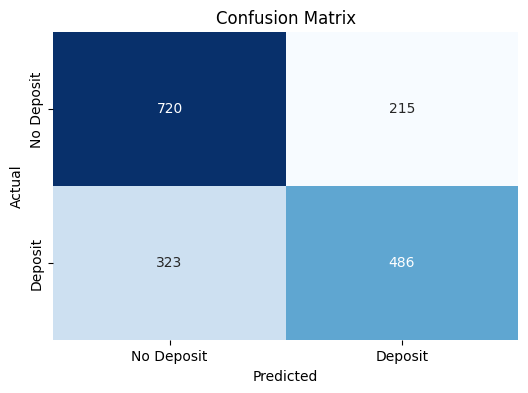


Classification Report:

              precision    recall  f1-score   support

  No Deposit       0.69      0.77      0.73       935
     Deposit       0.69      0.60      0.64       809

    accuracy                           0.69      1744
   macro avg       0.69      0.69      0.69      1744
weighted avg       0.69      0.69      0.69      1744

ROC-AUC: 0.7222424198356723


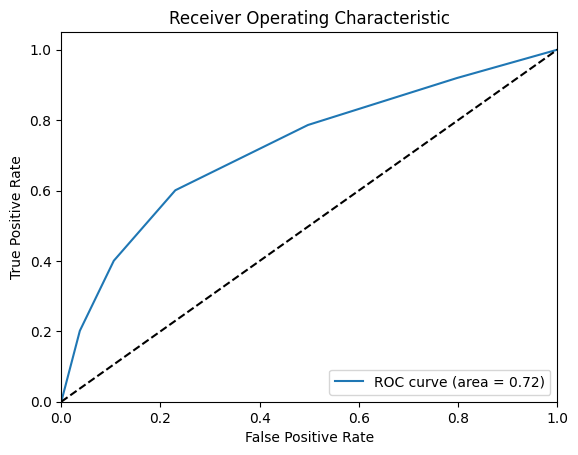

PR AUC: 0.6681678895926119


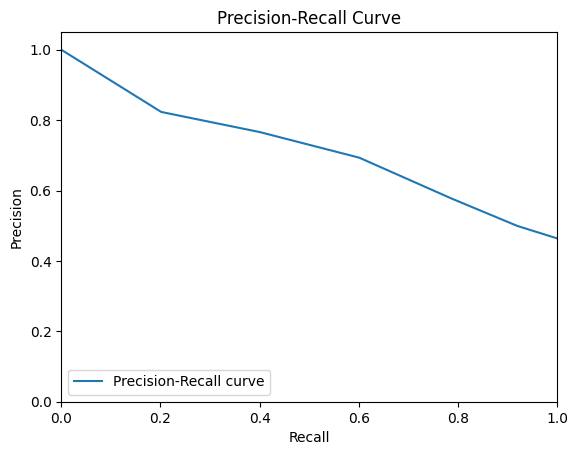

 15%|█▌        | 2/13 [00:02<00:14,  1.27s/it]


Confusion Matrix:
 [[818 117]
 [353 456]]


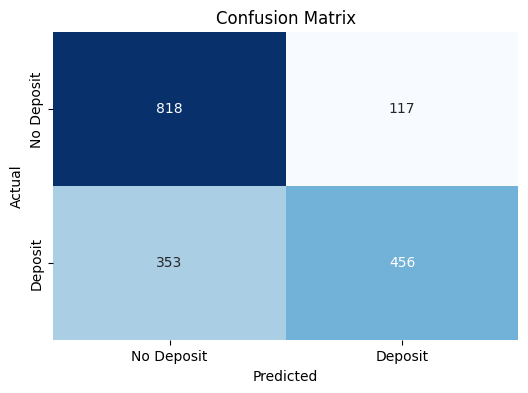


Classification Report:

              precision    recall  f1-score   support

  No Deposit       0.70      0.87      0.78       935
     Deposit       0.80      0.56      0.66       809

    accuracy                           0.73      1744
   macro avg       0.75      0.72      0.72      1744
weighted avg       0.74      0.73      0.72      1744

ROC-AUC: 0.7831521056562866


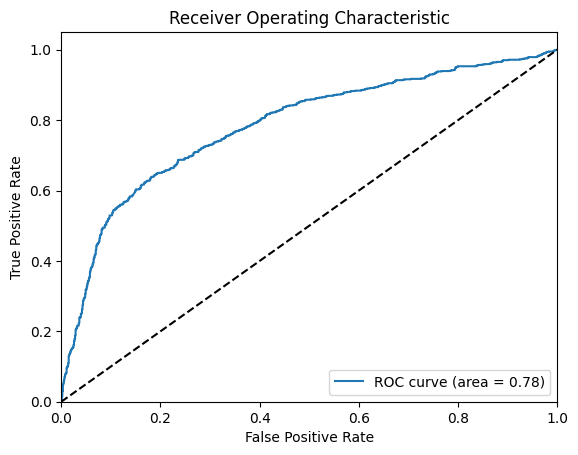

PR AUC: 0.7603392906738768


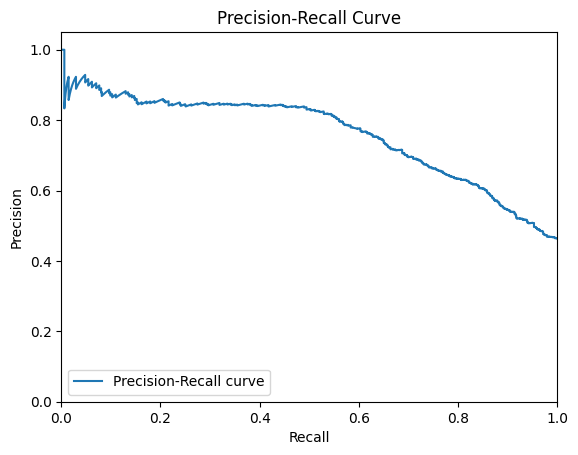

 23%|██▎       | 3/13 [00:21<01:35,  9.54s/it]


Confusion Matrix:
 [[641 294]
 [309 500]]


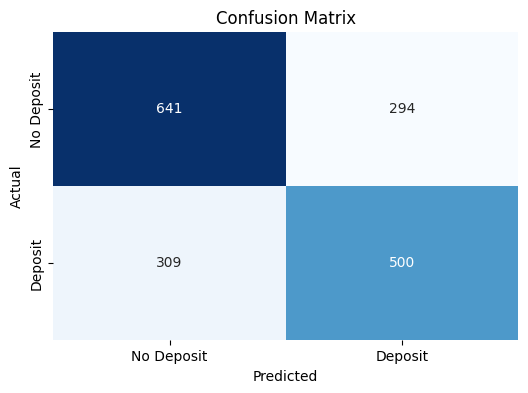


Classification Report:

              precision    recall  f1-score   support

  No Deposit       0.67      0.69      0.68       935
     Deposit       0.63      0.62      0.62       809

    accuracy                           0.65      1744
   macro avg       0.65      0.65      0.65      1744
weighted avg       0.65      0.65      0.65      1744

ROC-AUC: 0.6518042344480213


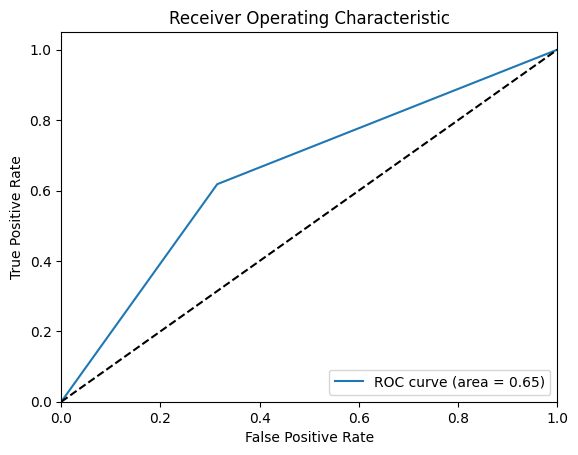

PR AUC: 0.566377243899848


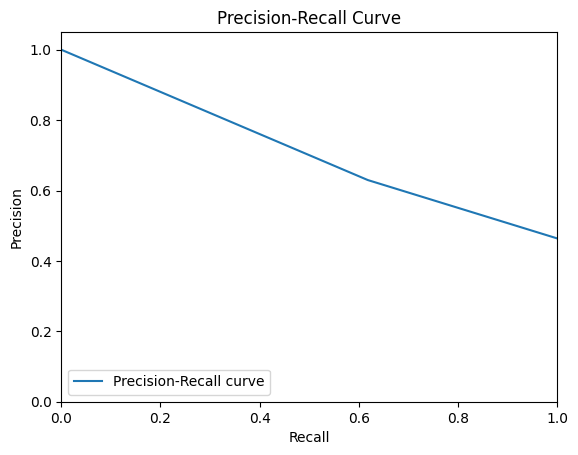

 31%|███       | 4/13 [00:22<00:53,  5.99s/it]


Confusion Matrix:
 [[775 160]
 [381 428]]


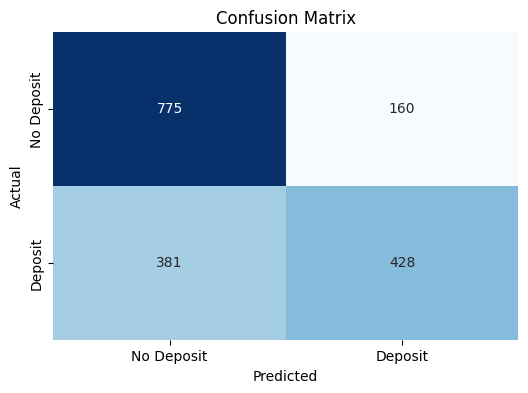


Classification Report:

              precision    recall  f1-score   support

  No Deposit       0.67      0.83      0.74       935
     Deposit       0.73      0.53      0.61       809

    accuracy                           0.69      1744
   macro avg       0.70      0.68      0.68      1744
weighted avg       0.70      0.69      0.68      1744

ROC-AUC: 0.739212601548092


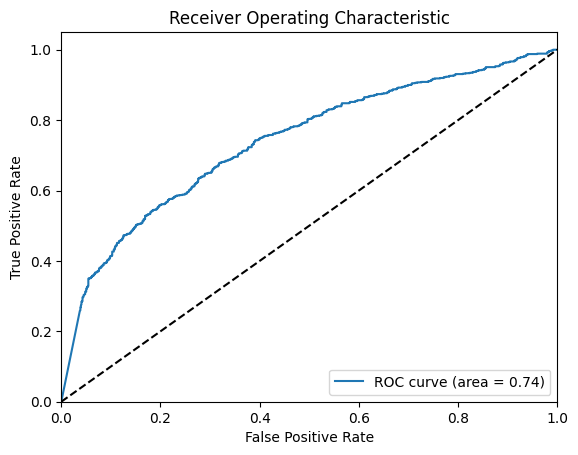

PR AUC: 0.7183655986445638


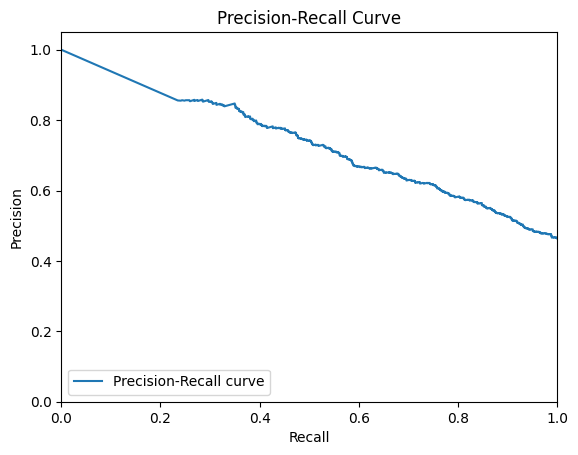

 38%|███▊      | 5/13 [00:22<00:31,  3.99s/it]


Confusion Matrix:
 [[744 191]
 [301 508]]


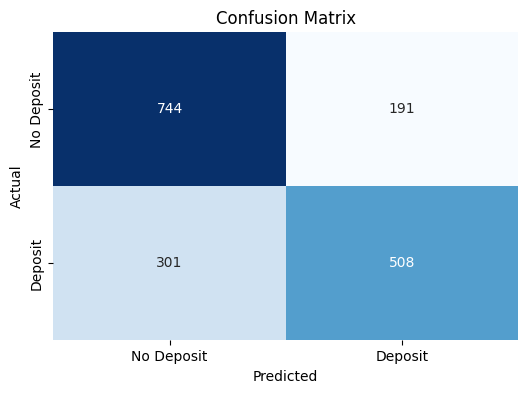


Classification Report:

              precision    recall  f1-score   support

  No Deposit       0.71      0.80      0.75       935
     Deposit       0.73      0.63      0.67       809

    accuracy                           0.72      1744
   macro avg       0.72      0.71      0.71      1744
weighted avg       0.72      0.72      0.72      1744

ROC-AUC: 0.7722103607146871


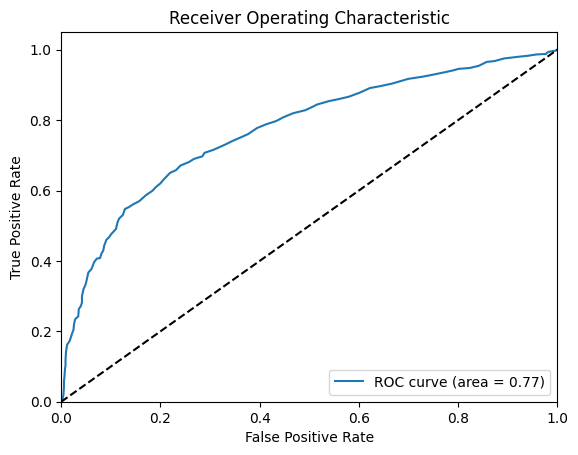

PR AUC: 0.7513448211627637


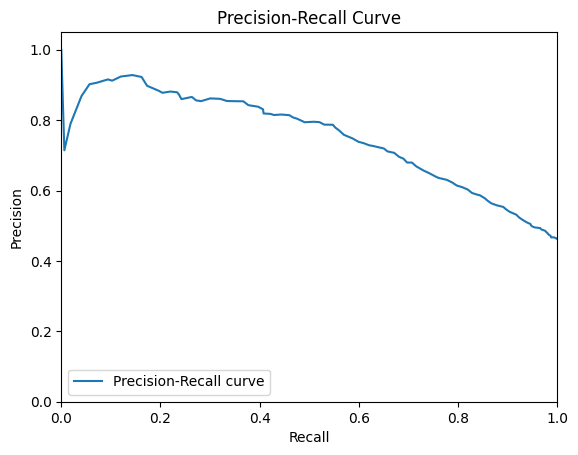

 46%|████▌     | 6/13 [00:24<00:22,  3.22s/it]


Confusion Matrix:
 [[699 236]
 [308 501]]


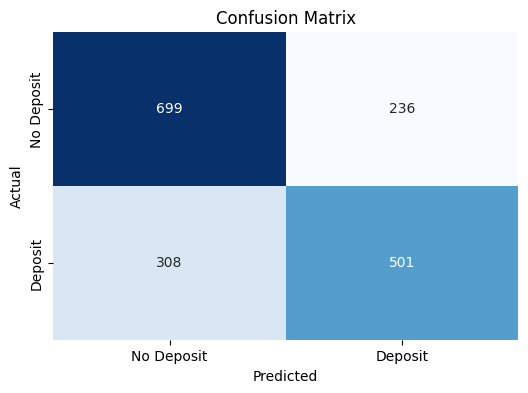


Classification Report:

              precision    recall  f1-score   support

  No Deposit       0.69      0.75      0.72       935
     Deposit       0.68      0.62      0.65       809

    accuracy                           0.69      1744
   macro avg       0.69      0.68      0.68      1744
weighted avg       0.69      0.69      0.69      1744

ROC-AUC: 0.740999319156812


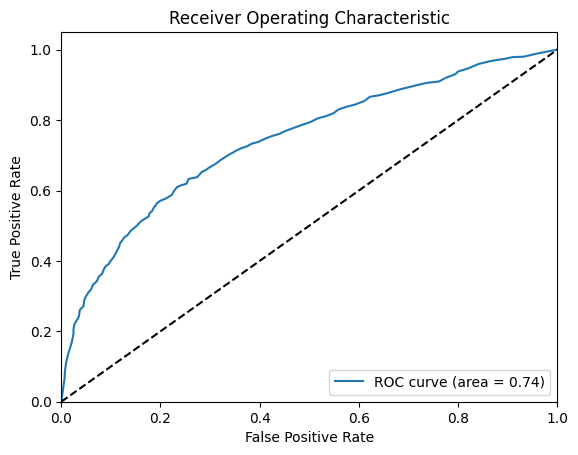

PR AUC: 0.7230119898773478


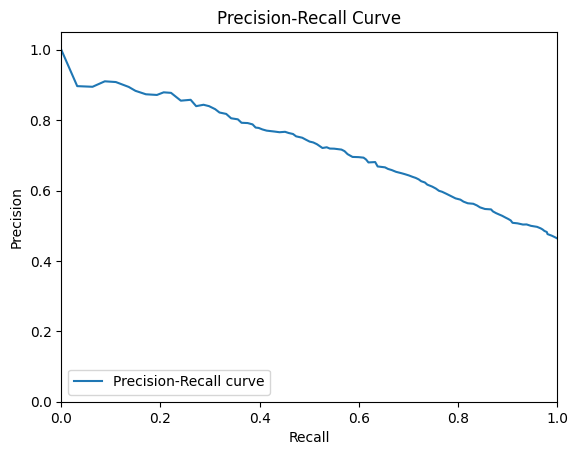

 54%|█████▍    | 7/13 [00:26<00:17,  2.86s/it]


Confusion Matrix:
 [[710 225]
 [313 496]]


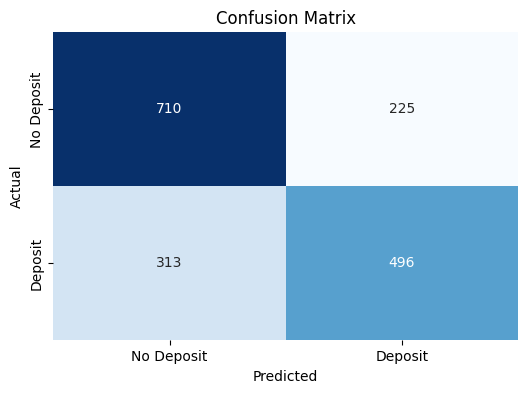


Classification Report:

              precision    recall  f1-score   support

  No Deposit       0.69      0.76      0.73       935
     Deposit       0.69      0.61      0.65       809

    accuracy                           0.69      1744
   macro avg       0.69      0.69      0.69      1744
weighted avg       0.69      0.69      0.69      1744

ROC-AUC: 0.7543755742548732


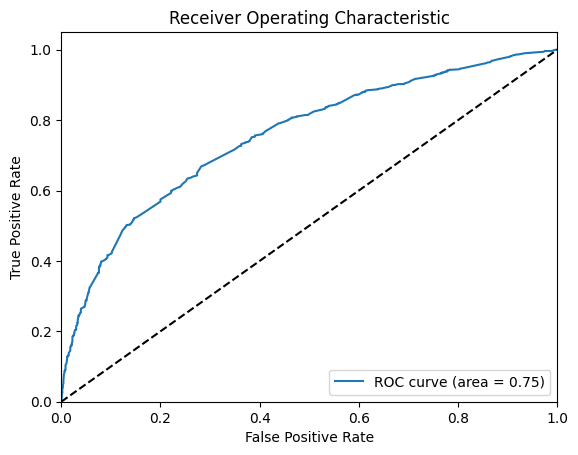

PR AUC: 0.733497170537778


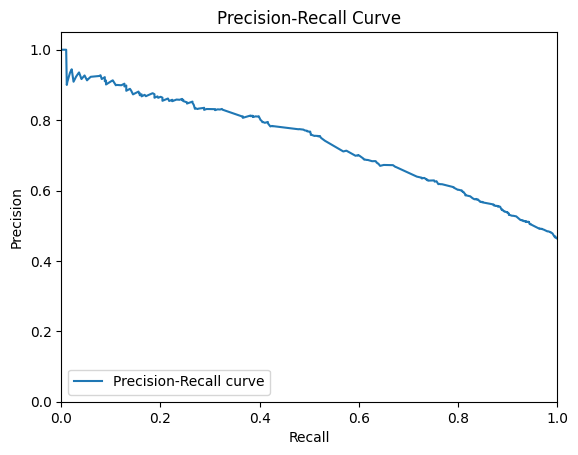

 62%|██████▏   | 8/13 [00:27<00:11,  2.35s/it]


Confusion Matrix:
 [[790 145]
 [326 483]]


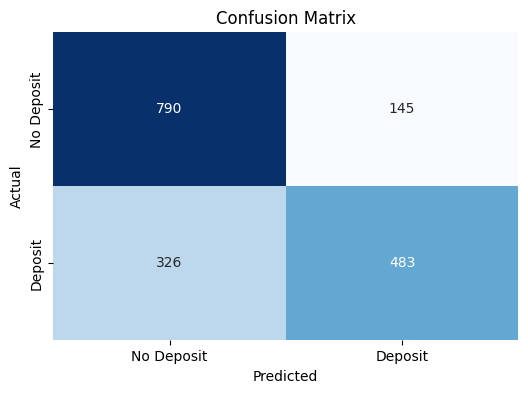


Classification Report:

              precision    recall  f1-score   support

  No Deposit       0.71      0.84      0.77       935
     Deposit       0.77      0.60      0.67       809

    accuracy                           0.73      1744
   macro avg       0.74      0.72      0.72      1744
weighted avg       0.74      0.73      0.72      1744

ROC-AUC: 0.7866250669275464


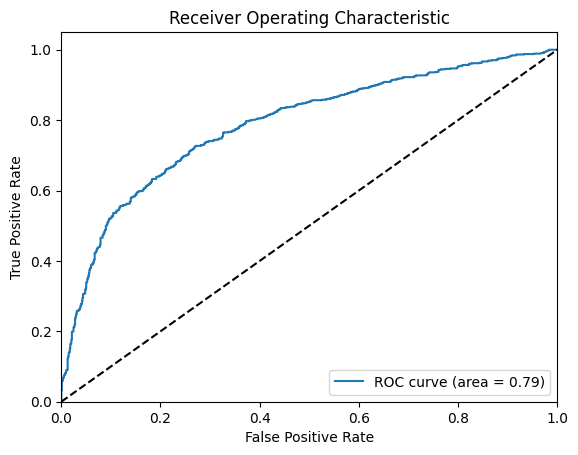

PR AUC: 0.7698116949000842


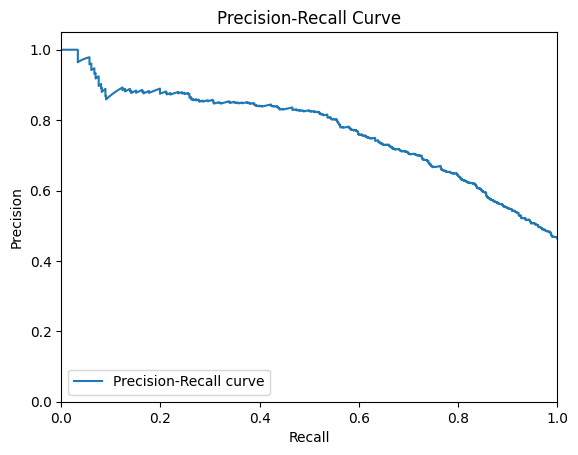

 69%|██████▉   | 9/13 [00:30<00:09,  2.30s/it]


Confusion Matrix:
 [[771 164]
 [307 502]]


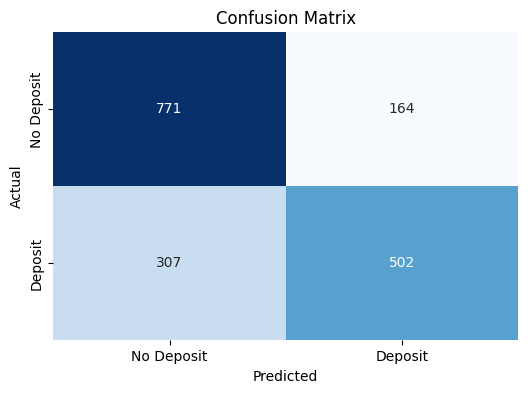


Classification Report:

              precision    recall  f1-score   support

  No Deposit       0.72      0.82      0.77       935
     Deposit       0.75      0.62      0.68       809

    accuracy                           0.73      1744
   macro avg       0.73      0.72      0.72      1744
weighted avg       0.73      0.73      0.73      1744

ROC-AUC: 0.7900292828672092


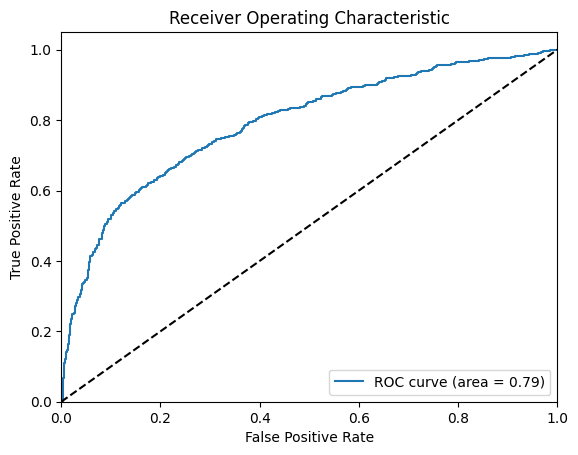

PR AUC: 0.7680416543180285


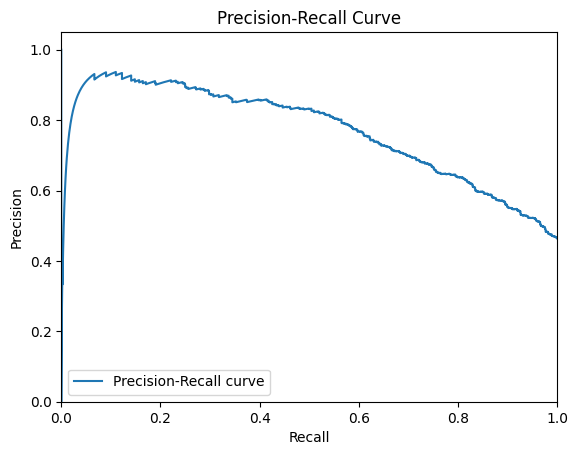

 77%|███████▋  | 10/13 [00:31<00:05,  1.95s/it]/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [14:57:13] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)



Confusion Matrix:
 [[744 191]
 [286 523]]


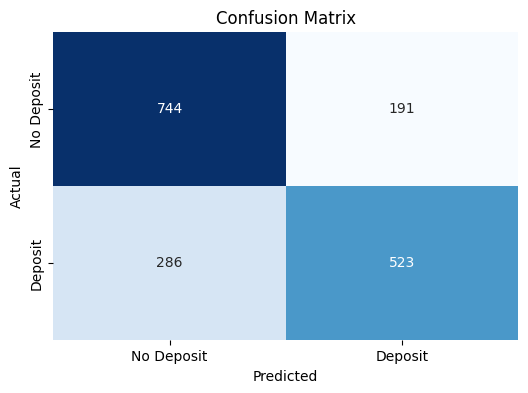


Classification Report:

              precision    recall  f1-score   support

  No Deposit       0.72      0.80      0.76       935
     Deposit       0.73      0.65      0.69       809

    accuracy                           0.73      1744
   macro avg       0.73      0.72      0.72      1744
weighted avg       0.73      0.73      0.72      1744

ROC-AUC: 0.7845587409028112


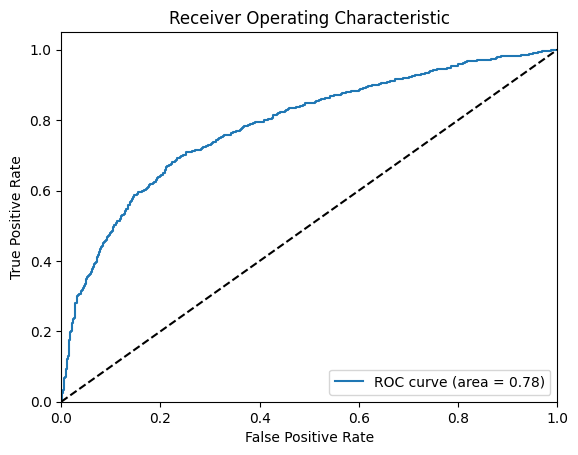

PR AUC: 0.7643474819449687


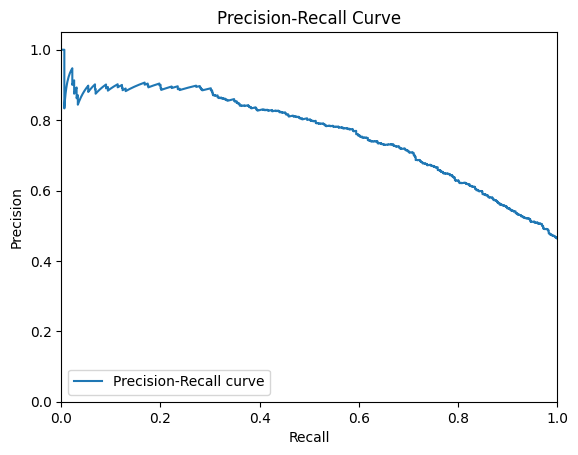

 85%|████████▍ | 11/13 [00:32<00:03,  1.58s/it]


Confusion Matrix:
 [[786 149]
 [304 505]]


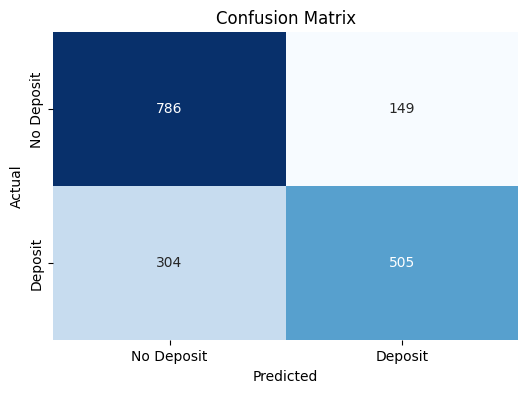


Classification Report:

              precision    recall  f1-score   support

  No Deposit       0.72      0.84      0.78       935
     Deposit       0.77      0.62      0.69       809

    accuracy                           0.74      1744
   macro avg       0.75      0.73      0.73      1744
weighted avg       0.74      0.74      0.74      1744

ROC-AUC: 0.7980817408433201


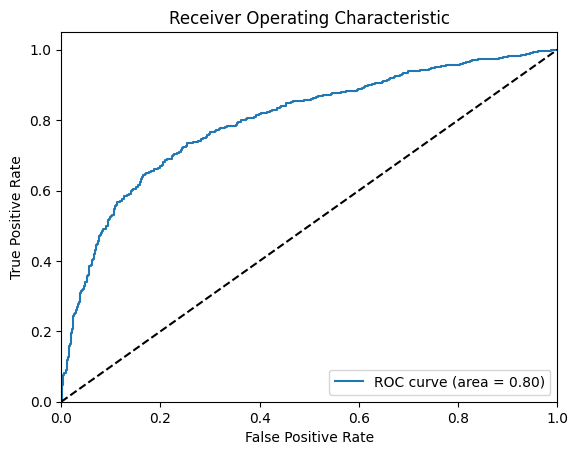

PR AUC: 0.7769308644820333


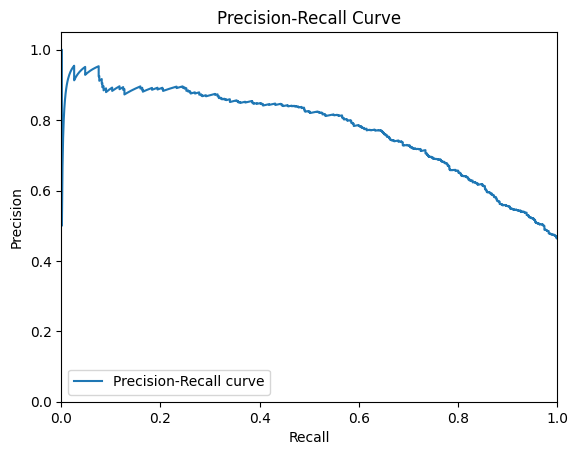

 92%|█████████▏| 12/13 [00:35<00:02,  2.32s/it]/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


[LightGBM] [Info] Number of positive: 3237, number of negative: 3738
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.003123 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 756
[LightGBM] [Info] Number of data points in the train set: 6975, number of used features: 50
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.464086 -> initscore=-0.143904
[LightGBM] [Info] Start training from score -0.143904

Confusion Matrix:
 [[772 163]
 [305 504]]


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


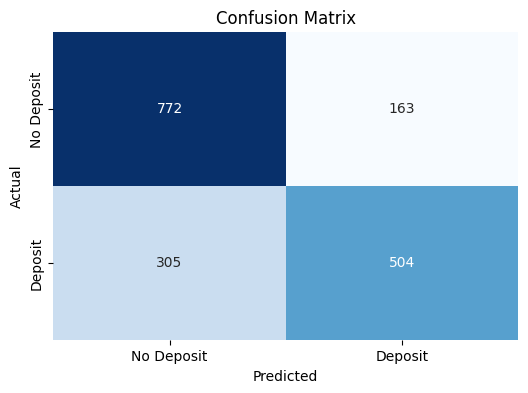

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(



Classification Report:

              precision    recall  f1-score   support

  No Deposit       0.72      0.83      0.77       935
     Deposit       0.76      0.62      0.68       809

    accuracy                           0.73      1744
   macro avg       0.74      0.72      0.73      1744
weighted avg       0.73      0.73      0.73      1744

ROC-AUC: 0.7916791708255388


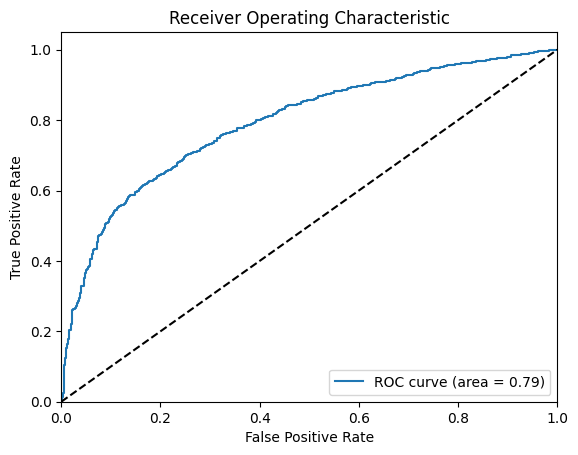

PR AUC: 0.7727645801603169


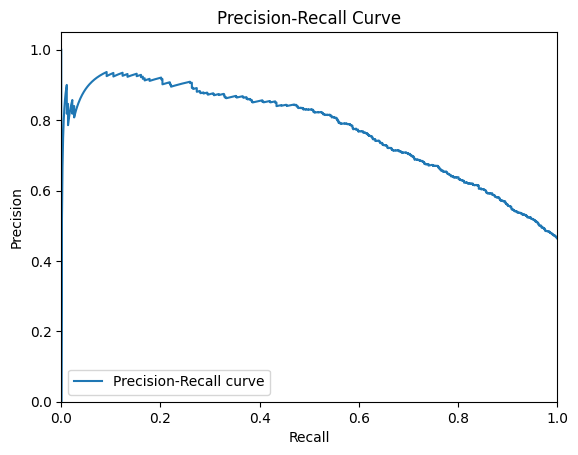

100%|██████████| 13/13 [00:36<00:00,  2.83s/it]


In [64]:
results = {}

for name, model in tqdm(models.items()):
    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    test_pred  = model.predict(X_test)



    cm = confusion_matrix(y_test, test_pred)
    print("\nConfusion Matrix:\n", cm)

    plt.figure(figsize=(6,4))
    sns.heatmap(cm,annot=True,fmt="d",cmap='Blues',cbar=False,
                xticklabels=['No Deposit','Deposit']
                ,yticklabels=['No Deposit','Deposit'])
    plt.ylabel('Actual')
    plt.xlabel('Predicted')
    plt.title('Confusion Matrix')
    plt.show()

    # Full classification report
    print("\nClassification Report:\n")
    print(classification_report(y_test, test_pred,target_names=['No Deposit','Deposit'],zero_division=0))

    y_pred_prob = model.predict_proba(X_test)[:, 1]
    roc_auc = roc_auc_score(y_test, y_pred_prob)
    print("ROC-AUC:", roc_auc)

    # ROC curve
    fpr, tpr, roc_thresholds = roc_curve(y_test, y_pred_prob)
    plt.figure()
    plt.plot(fpr, tpr, label='ROC curve (area = {:.2f})'.format(roc_auc))
    plt.plot([0, 1], [0, 1], 'k--')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Receiver Operating Characteristic')
    plt.legend(loc="lower right")
    plt.show()

    pr_auc = average_precision_score(y_test, y_pred_prob)
    print("PR AUC:", pr_auc)

    precision_vals, recall_vals, pr_thresholds = precision_recall_curve(y_test, y_pred_prob)
    plt.figure()
    plt.plot(recall_vals, precision_vals, label='Precision-Recall curve')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('Recall')
    plt.ylabel('Precision')
    plt.title('Precision-Recall Curve')
    plt.legend(loc="lower left")
    plt.show()

    results[name] = {
        "Train Accuracy": accuracy_score(y_train, train_pred),
        "Test Accuracy": accuracy_score(y_test, test_pred),
        "Train Precision": precision_score(y_train, train_pred),
        "Test Precision": precision_score(y_test, test_pred),
        "Train Recall": recall_score(y_train, train_pred),
        "Test Recall": recall_score(y_test, test_pred),
        "Train F1 Score": f1_score(y_train, train_pred),
        "Test F1 Score": f1_score(y_test, test_pred),
        "Train Balanced Accuracy": balanced_accuracy_score(y_train, train_pred),
        "Test Balanced Accuracy": balanced_accuracy_score(y_test, test_pred),
        "ROC-AUC": roc_auc,
        "PR AUC": pr_auc

    }

/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [14:57:20] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)



Confusion Matrix:
 [[792 143]
 [345 464]]


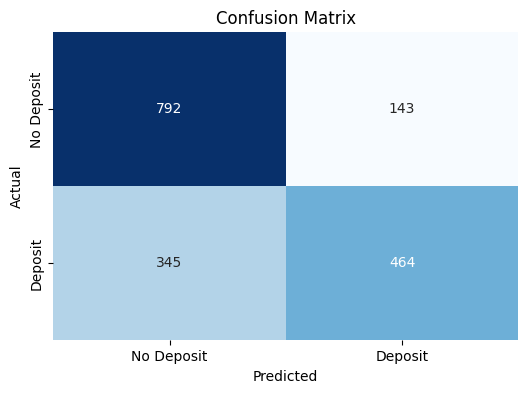


Classification Report:

              precision    recall  f1-score   support

  No Deposit       0.70      0.85      0.76       935
     Deposit       0.76      0.57      0.66       809

    accuracy                           0.72      1744
   macro avg       0.73      0.71      0.71      1744
weighted avg       0.73      0.72      0.71      1744

ROC-AUC: 0.7826867526423986


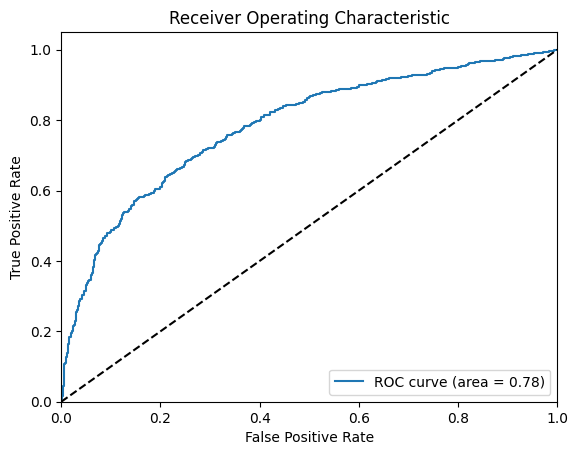

PR AUC: 0.762202913668629


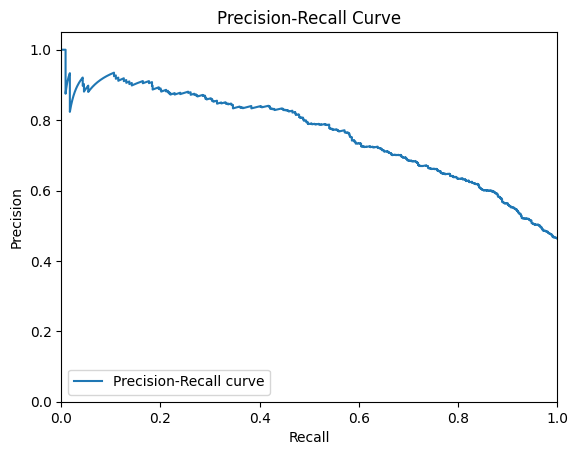

In [65]:
voting_model = VotingClassifier(
    estimators=[
        ("lr", models["Logistic Regression"]),
        ("rf", models["Random Forest"]),
        ("nb", models["Naive Bayes"]),
        ("xgb", models["XGBoost"]),
    ],
    voting="soft" # voting='hard' / voting='soft', weights=[2, 1, 2,1]
)

voting_model.fit(X_train, y_train)
voting_train_pred = voting_model.predict(X_train)
voting_test_pred = voting_model.predict(X_test)


cm = confusion_matrix(y_test, voting_test_pred)
print("\nConfusion Matrix:\n", cm)

plt.figure(figsize=(6,4))
sns.heatmap(cm,annot=True,fmt="d",cmap='Blues',cbar=False,
             xticklabels=['No Deposit','Deposit']
            ,yticklabels=['No Deposit','Deposit'])
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.title('Confusion Matrix')
plt.show()

# Full classification report
print("\nClassification Report:\n")
print(classification_report(y_test, voting_test_pred,target_names=['No Deposit','Deposit'],zero_division=0))

y_pred_prob = voting_model.predict_proba(X_test)[:, 1]
roc_auc = roc_auc_score(y_test, y_pred_prob)
print("ROC-AUC:", roc_auc)

# ROC curve
fpr, tpr, roc_thresholds = roc_curve(y_test, y_pred_prob)
plt.figure()
plt.plot(fpr, tpr, label='ROC curve (area = {:.2f})'.format(roc_auc))
plt.plot([0, 1], [0, 1], 'k--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")
plt.show()

pr_auc = average_precision_score(y_test, y_pred_prob)
print("PR AUC:", pr_auc)

precision_vals, recall_vals, pr_thresholds = precision_recall_curve(y_test, y_pred_prob)
plt.figure()
plt.plot(recall_vals, precision_vals, label='Precision-Recall curve')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend(loc="lower left")
plt.show()

results["Voting Classifier"] = {
    "Train Accuracy": accuracy_score(y_train, voting_train_pred),
    "Test Accuracy": accuracy_score(y_test, voting_test_pred),
    "Train Precision": precision_score(y_train, voting_train_pred),
    "Test Precision": precision_score(y_test, voting_test_pred),
    "Train Recall": recall_score(y_train, voting_train_pred),
    "Test Recall": recall_score(y_test, voting_test_pred),
    "Train F1 Score": f1_score(y_train, voting_train_pred),
    "Test F1 Score": f1_score(y_test, voting_test_pred),
    "Train Balanced Accuracy": balanced_accuracy_score(y_train, voting_train_pred),
    "Test Balanced Accuracy": balanced_accuracy_score(y_test, voting_test_pred),
    "ROC-AUC": roc_auc,
    "PR AUC": pr_auc
}

/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [14:57:38] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "max_iter" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(



Confusion Matrix:
 [[731 204]
 [322 487]]


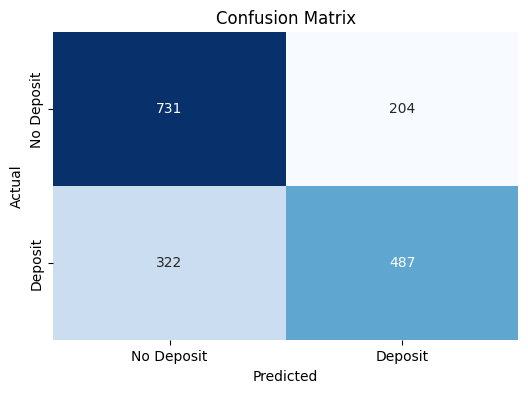


Classification Report:

              precision    recall  f1-score   support

  No Deposit       0.69      0.78      0.74       935
     Deposit       0.70      0.60      0.65       809

    accuracy                           0.70      1744
   macro avg       0.70      0.69      0.69      1744
weighted avg       0.70      0.70      0.70      1744



/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


ROC-AUC: 0.7543412015890748


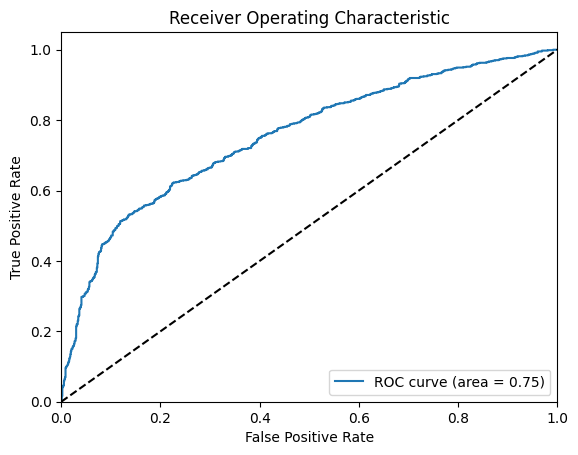

PR AUC: 0.7353622480343489


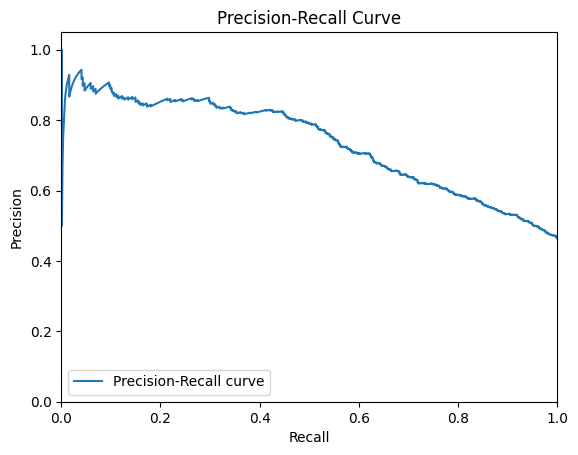

In [66]:
stack_auto = StackingClassifier(
    estimators=[
        ("lr", models["Logistic Regression"]),
        ("rf", models["Random Forest"]),
        ("nb", models["Naive Bayes"]),
        ("lgbm", models["LightGBM"]),


    ],
    final_estimator=XGBClassifier(max_iter=2000),
    stack_method="predict_proba",   # best for classification usually
    n_jobs=-1
)

# Train
stack_auto.fit(X_train, y_train)

# Predictions
stack_auto_train_pred = stack_auto.predict(X_train)
stack_auto_test_pred  = stack_auto.predict(X_test)

cm = confusion_matrix(y_test, stack_auto_test_pred)
print("\nConfusion Matrix:\n", cm)

plt.figure(figsize=(6,4))
sns.heatmap(cm,annot=True,fmt="d",cmap='Blues',cbar=False,
             xticklabels=['No Deposit','Deposit']
            ,yticklabels=['No Deposit','Deposit'])
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.title('Confusion Matrix')
plt.show()

# Full classification report
print("\nClassification Report:\n")
print(classification_report(y_test, stack_auto_test_pred,target_names=['No Deposit','Deposit'],zero_division=0))

y_pred_prob = stack_auto.predict_proba(X_test)[:, 1]
roc_auc = roc_auc_score(y_test, y_pred_prob)
print("ROC-AUC:", roc_auc)

# ROC curve
fpr, tpr, roc_thresholds = roc_curve(y_test, y_pred_prob)
plt.figure()
plt.plot(fpr, tpr, label='ROC curve (area = {:.2f})'.format(roc_auc))
plt.plot([0, 1], [0, 1], 'k--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")
plt.show()

pr_auc = average_precision_score(y_test, y_pred_prob)
print("PR AUC:", pr_auc)

precision_vals, recall_vals, pr_thresholds = precision_recall_curve(y_test, y_pred_prob)
plt.figure()
plt.plot(recall_vals, precision_vals, label='Precision-Recall curve')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend(loc="lower left")
plt.show()

results["Stacking Classifier "] = {
    "Train Accuracy": accuracy_score(y_train, stack_auto_train_pred),
    "Test Accuracy": accuracy_score(y_test, stack_auto_test_pred),
    "Train Precision": precision_score(y_train, stack_auto_train_pred),
    "Test Precision": precision_score(y_test, stack_auto_test_pred),
    "Train Recall": recall_score(y_train, stack_auto_train_pred),
    "Test Recall": recall_score(y_test, stack_auto_test_pred),
    "Train F1 Score": f1_score(y_train, stack_auto_train_pred),
    "Test F1 Score": f1_score(y_test, stack_auto_test_pred),
    "Train Balanced Accuracy": balanced_accuracy_score(y_train, stack_auto_train_pred),
    "Test Balanced Accuracy": balanced_accuracy_score(y_test, stack_auto_test_pred),
    "ROC-AUC": roc_auc,
    "PR AUC": pr_auc
}

In [67]:
results_df = pd.DataFrame(results).T
results_df = results_df.sort_values(by="Test F1 Score", ascending=False)
results_df

,Train Accuracy,Test Accuracy,Train Precision,Test Precision,Train Recall,Test Recall,Train F1 Score,Test F1 Score,Train Balanced Accuracy,Test Balanced Accuracy,ROC-AUC,PR AUC
CatBoost,0.824803,0.740252,0.870813,0.772171,0.730924,0.624227,0.794760,0.690362,0.818512,0.732435,0.798082,0.776931
XGBoost,0.892760,0.726491,0.936208,0.732493,0.825147,0.646477,0.877176,0.686802,0.888229,0.721100,0.784559,0.764347
LightGBM,0.826810,0.731651,0.872841,0.755622,0.733704,0.622991,0.797247,0.682927,0.820571,0.724330,0.791679,0.772765
Hist Gradient Boosting,0.825520,0.729931,0.869693,0.753754,0.734013,0.620519,0.796113,0.680678,0.819387,0.722559,0.790029,0.768042
Random Forest,1.000000,0.717890,1.000000,0.726753,1.000000,0.627936,1.000000,0.673740,1.000000,0.711829,0.772210,0.751345
Gradient Boosting,0.767312,0.729931,0.812791,0.769108,0.647822,0.597033,0.720990,0.672234,0.759304,0.720977,0.786625,0.769812
SVC,0.773763,0.730505,0.851334,0.795812,0.620945,0.563659,0.718114,0.659913,0.763522,0.719263,0.783152,0.760339
Voting Classifier,0.814910,0.720183,0.880673,0.764415,0.695397,0.573548,0.777145,0.655367,0.806901,0.710303,0.782687,0.762203
Logistic Regression,0.725591,0.706422,0.756098,0.721973,0.603336,0.597033,0.671134,0.653586,0.717399,0.699051,0.765388,0.748893
Stacking Classifier,0.786237,0.698394,0.807178,0.704776,0.708681,0.601978,0.754729,0.649333,0.781039,0.691898,0.754341,0.735362


<Axes: >

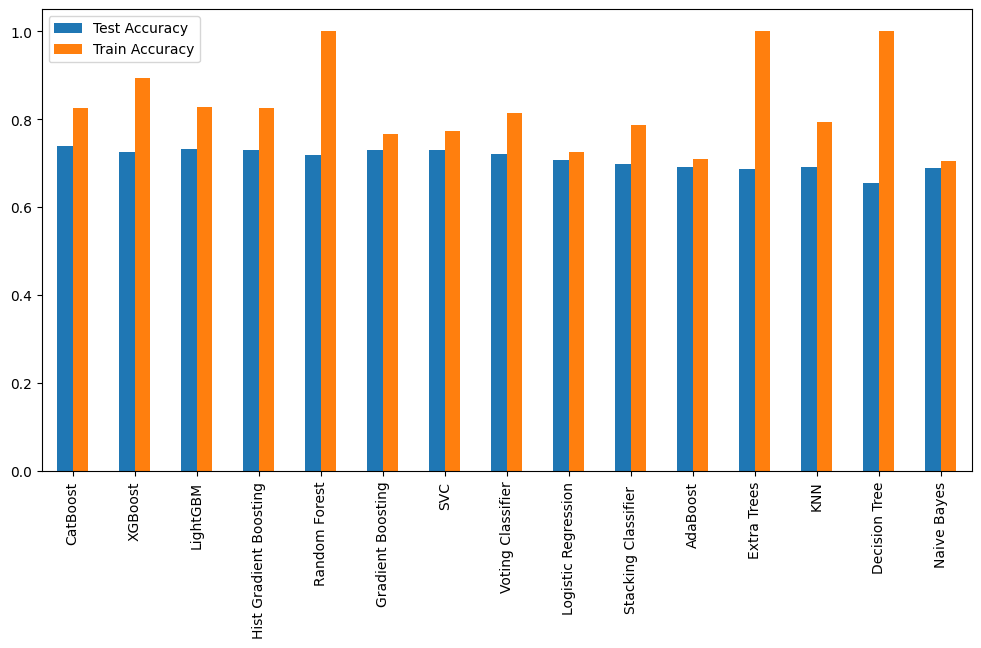

In [68]:
results_df[["Test Accuracy", "Train Accuracy"]].plot.bar(figsize=(12,6))

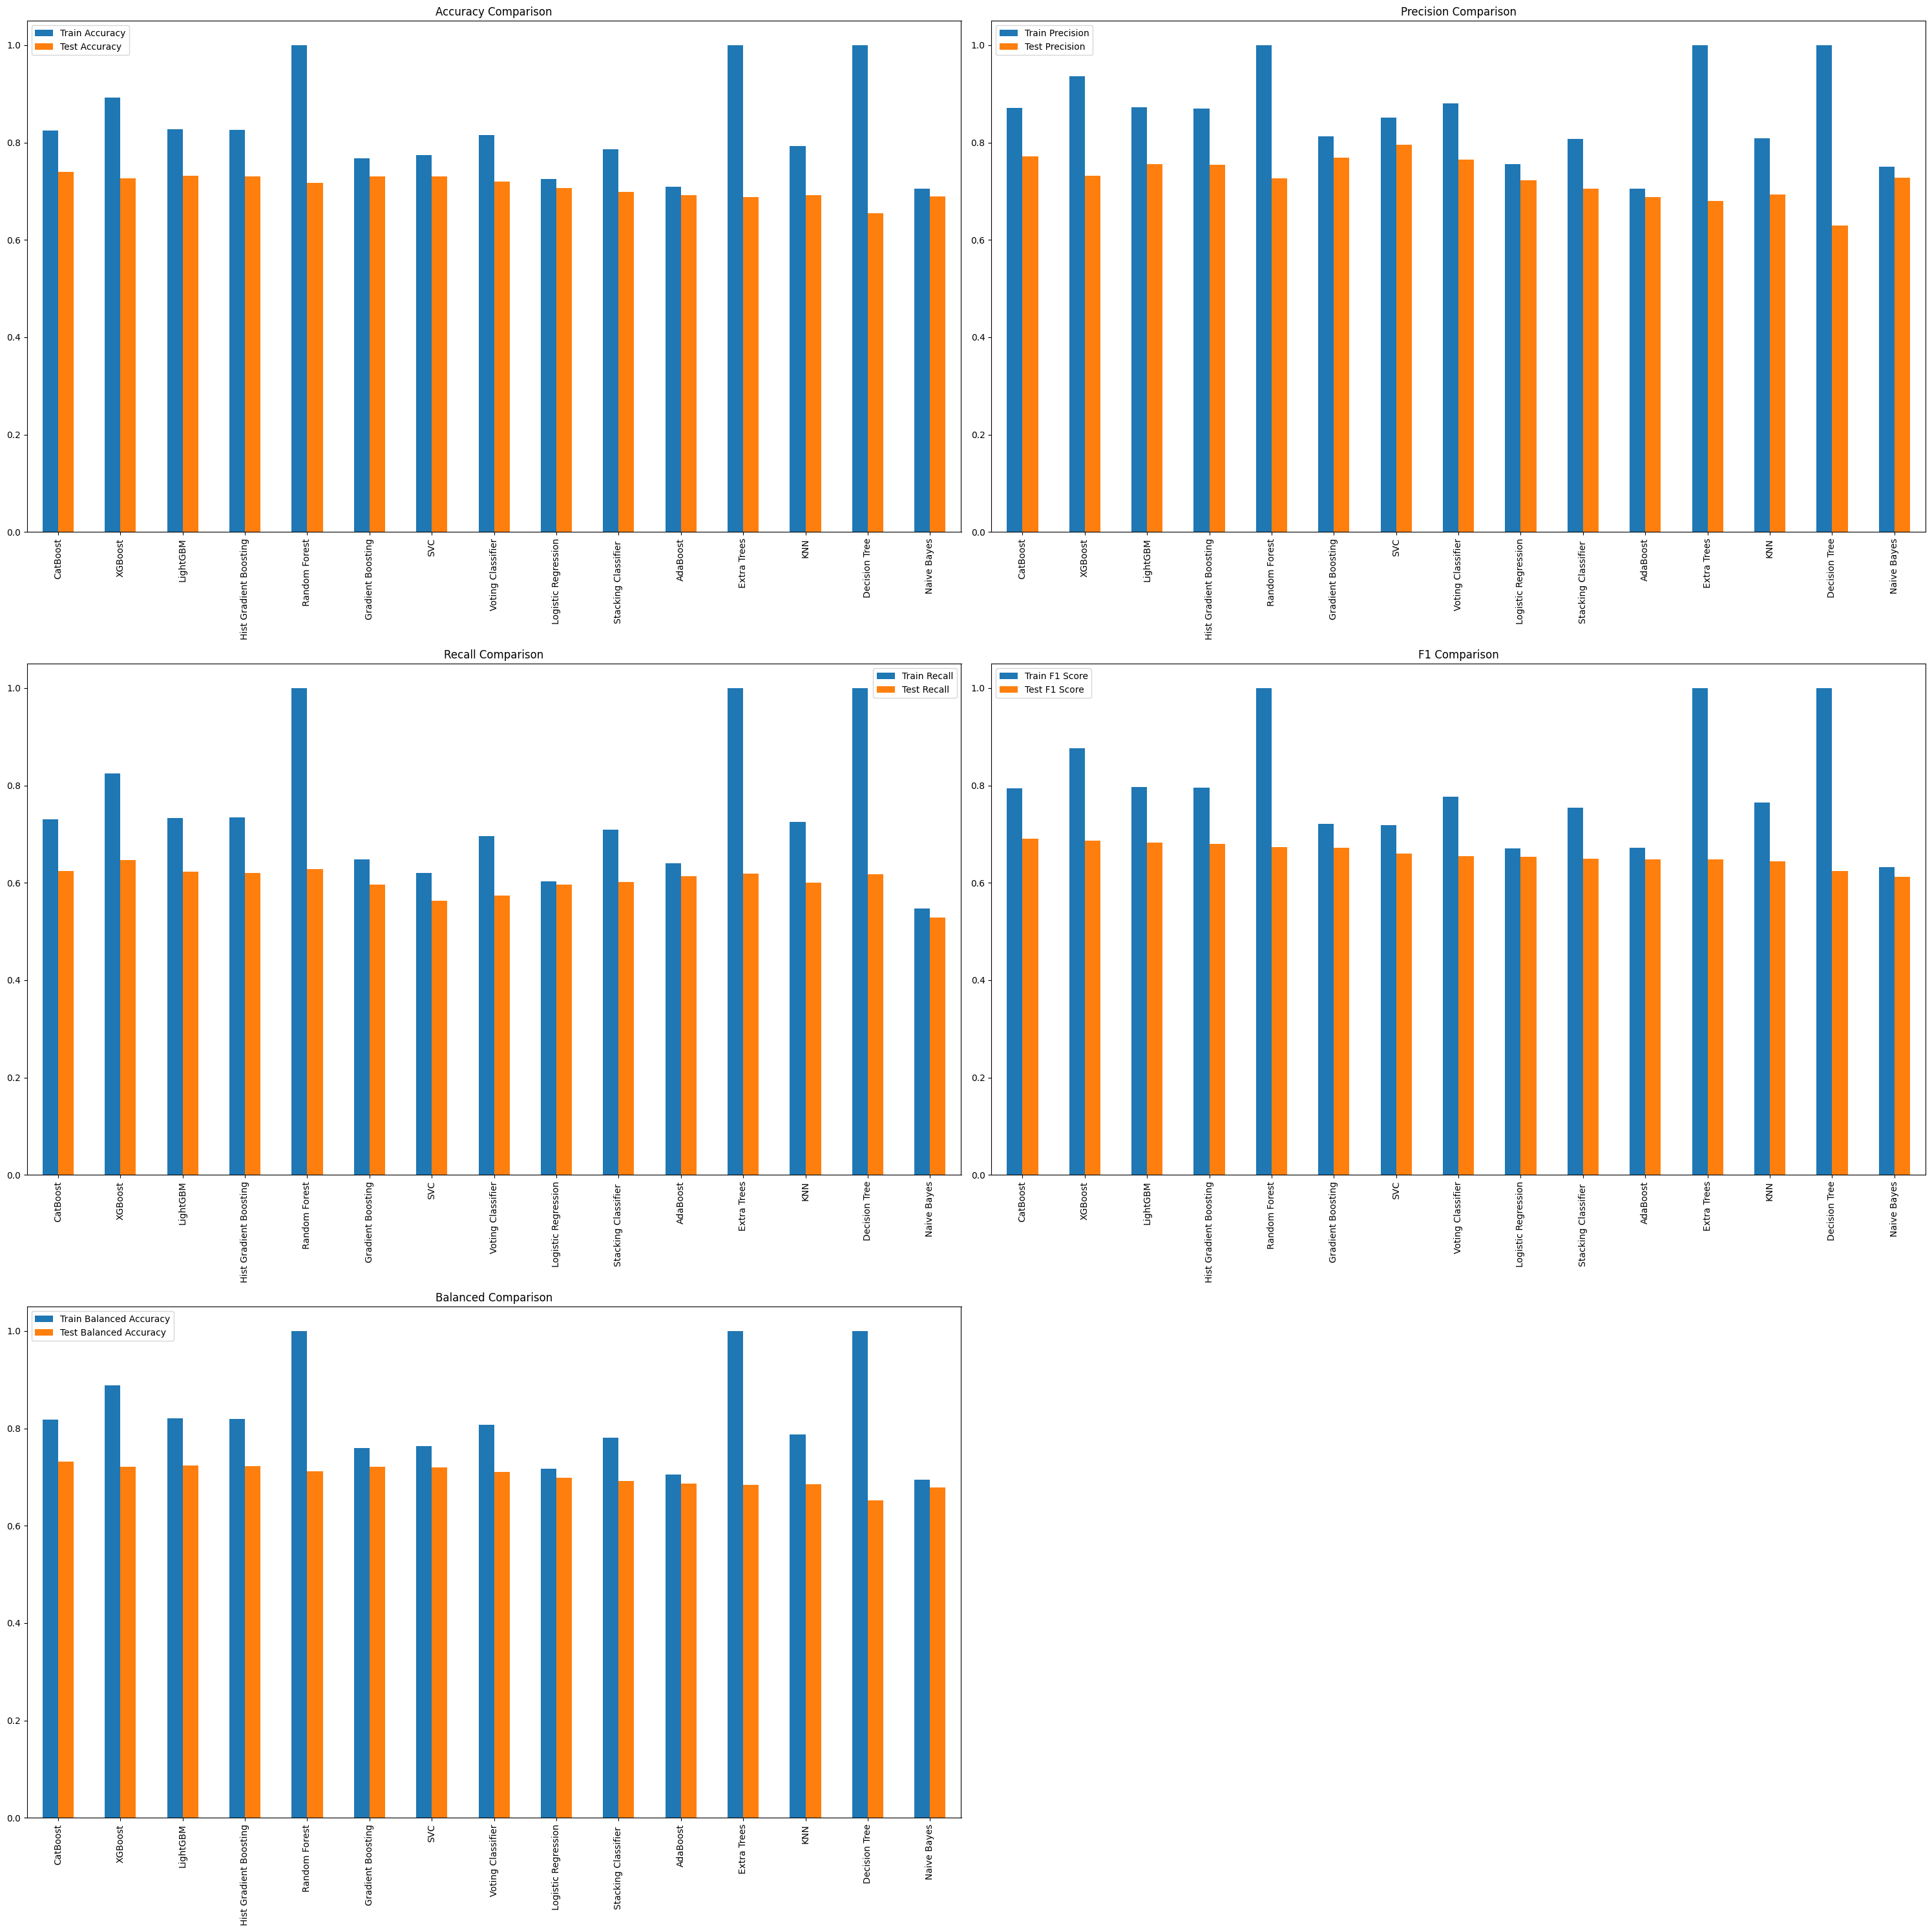

In [69]:
cols = [
    ['Train Accuracy', 'Test Accuracy'],
    ['Train Precision', 'Test Precision'],
    ['Train Recall', 'Test Recall'],
    ['Train F1 Score', 'Test F1 Score'],
    ["Train Balanced Accuracy", "Test Balanced Accuracy"]
]

plt.figure(figsize=(30,30))

for i, col in enumerate(cols):
    ax = plt.subplot(3, 2, i+1)
    results_df[col].plot.bar(ax=ax)
    ax.set_title(col[0].split(" ")[1] + ' Comparison')

plt.tight_layout()
plt.show()